# **STEP 3, PART 1.3**

### **Displays of best grid-search models.**

In [1]:
import sys, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_fits, load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *
from sigma_comp import *

LAB_PATH = "../Displays/lab.fit.gz"
PRODUCTS = "../Convergence/lab_products.npz"         # written by background_remove.ipynb: the LAB cube to use and its sigma
GRID = Path("../Convergence/grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("../Convergence/conv")                   # the convergence-study cubes (tiers 1-4)
PLOT = Path("./plots")
B_CUT = 0
L_CUT = 0
V_DEV = 35.0                            # km/s: |v_dev| below this is disc (Marasco+12 sect. 2.4: 35)
REL_FLOOR = 0.04                        # K: softening of the relative residual (see the module docstring)
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

In [2]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR)

SIGMA = P.sigma_empty
print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: lab_background_correction.npz
Comparison grid: 62 channels x 41 b x 90 l; 163347 LAB voxels with data


In [3]:
if False:
    from mw_init import param
    from mw_cube import create_cube_MW
    param.init_params_MW(
            path_yaml="input_MW.yaml",
            path_sfr_profile="sfr_profile_marasco12.txt",
            l_min=0.0, l_max=360.0, dl=1.0,
            b_min=0.0, b_max=90.0, db=1.0,
            v_min=-400.0, v_max=400.0, dv=4.0,
            R0_kpc=8.275, z_sun_kpc=0.0, v_sun_kms=(0.0, None, 0.0),
            path_to_files="../Tests/inputs/",
            shift_l0_to_center=True,
            hush_print=True,
        )

    if False:
        _ =create_cube_MW(hv0=79.273, alpha_conds=9.999, alpha_hv=0.500, f_ion=0.0, vlag=75.0, 
            R_disk=30, min_R=0.5, max_R=20, dR=0.25, n_per_bin=40, n_iter_add=900, R_clump=0.1,
            seed=100, azimuth_seed=1000, save_result_to="./best_model.npz")

    if False:
        _ =create_cube_MW(hv0=59.631, alpha_conds=5.579, alpha_hv=0.0, f_ion=0.152, vlag=103.903, 
            R_disk=30, min_R=0.5, max_R=20, dR=0.25, n_per_bin=40, n_iter_add=900, R_clump=0.1,
            seed=100, azimuth_seed=1000, save_result_to="./best_model_ahv0.npz")

else:
    print("Best models have been generated on disk.")

Best models have been generated on disk.


In [4]:
RES = {}; MODS = {}

def evaluate_models(names, folder, keep_vec_for=()):
    for nm in names:
        f = Path(folder) / f"{nm}.npz"
        if nm in RES or not f.exists():
            continue
        cube, ax = load_model(nm, folder)
        mod = cmp.model_cmp(cube, ax)
        RES[nm] = cmp.evaluate(mod, keep_vectors=(nm in keep_vec_for)); MODS[nm] = mod

M_INDEX = 2000
LABELS = {0: "neutral", 1: "ionised", 2: "condensation"}
names_M = [f"M{M_INDEX + i:04d}" for i in range(9)]

evaluate_models(names_M, GRID, keep_vec_for=tuple(names_M))

evaluate_models(["best_model", "best_model_ahv0"], "./", keep_vec_for=("best_model", "best_model_ahv0"))

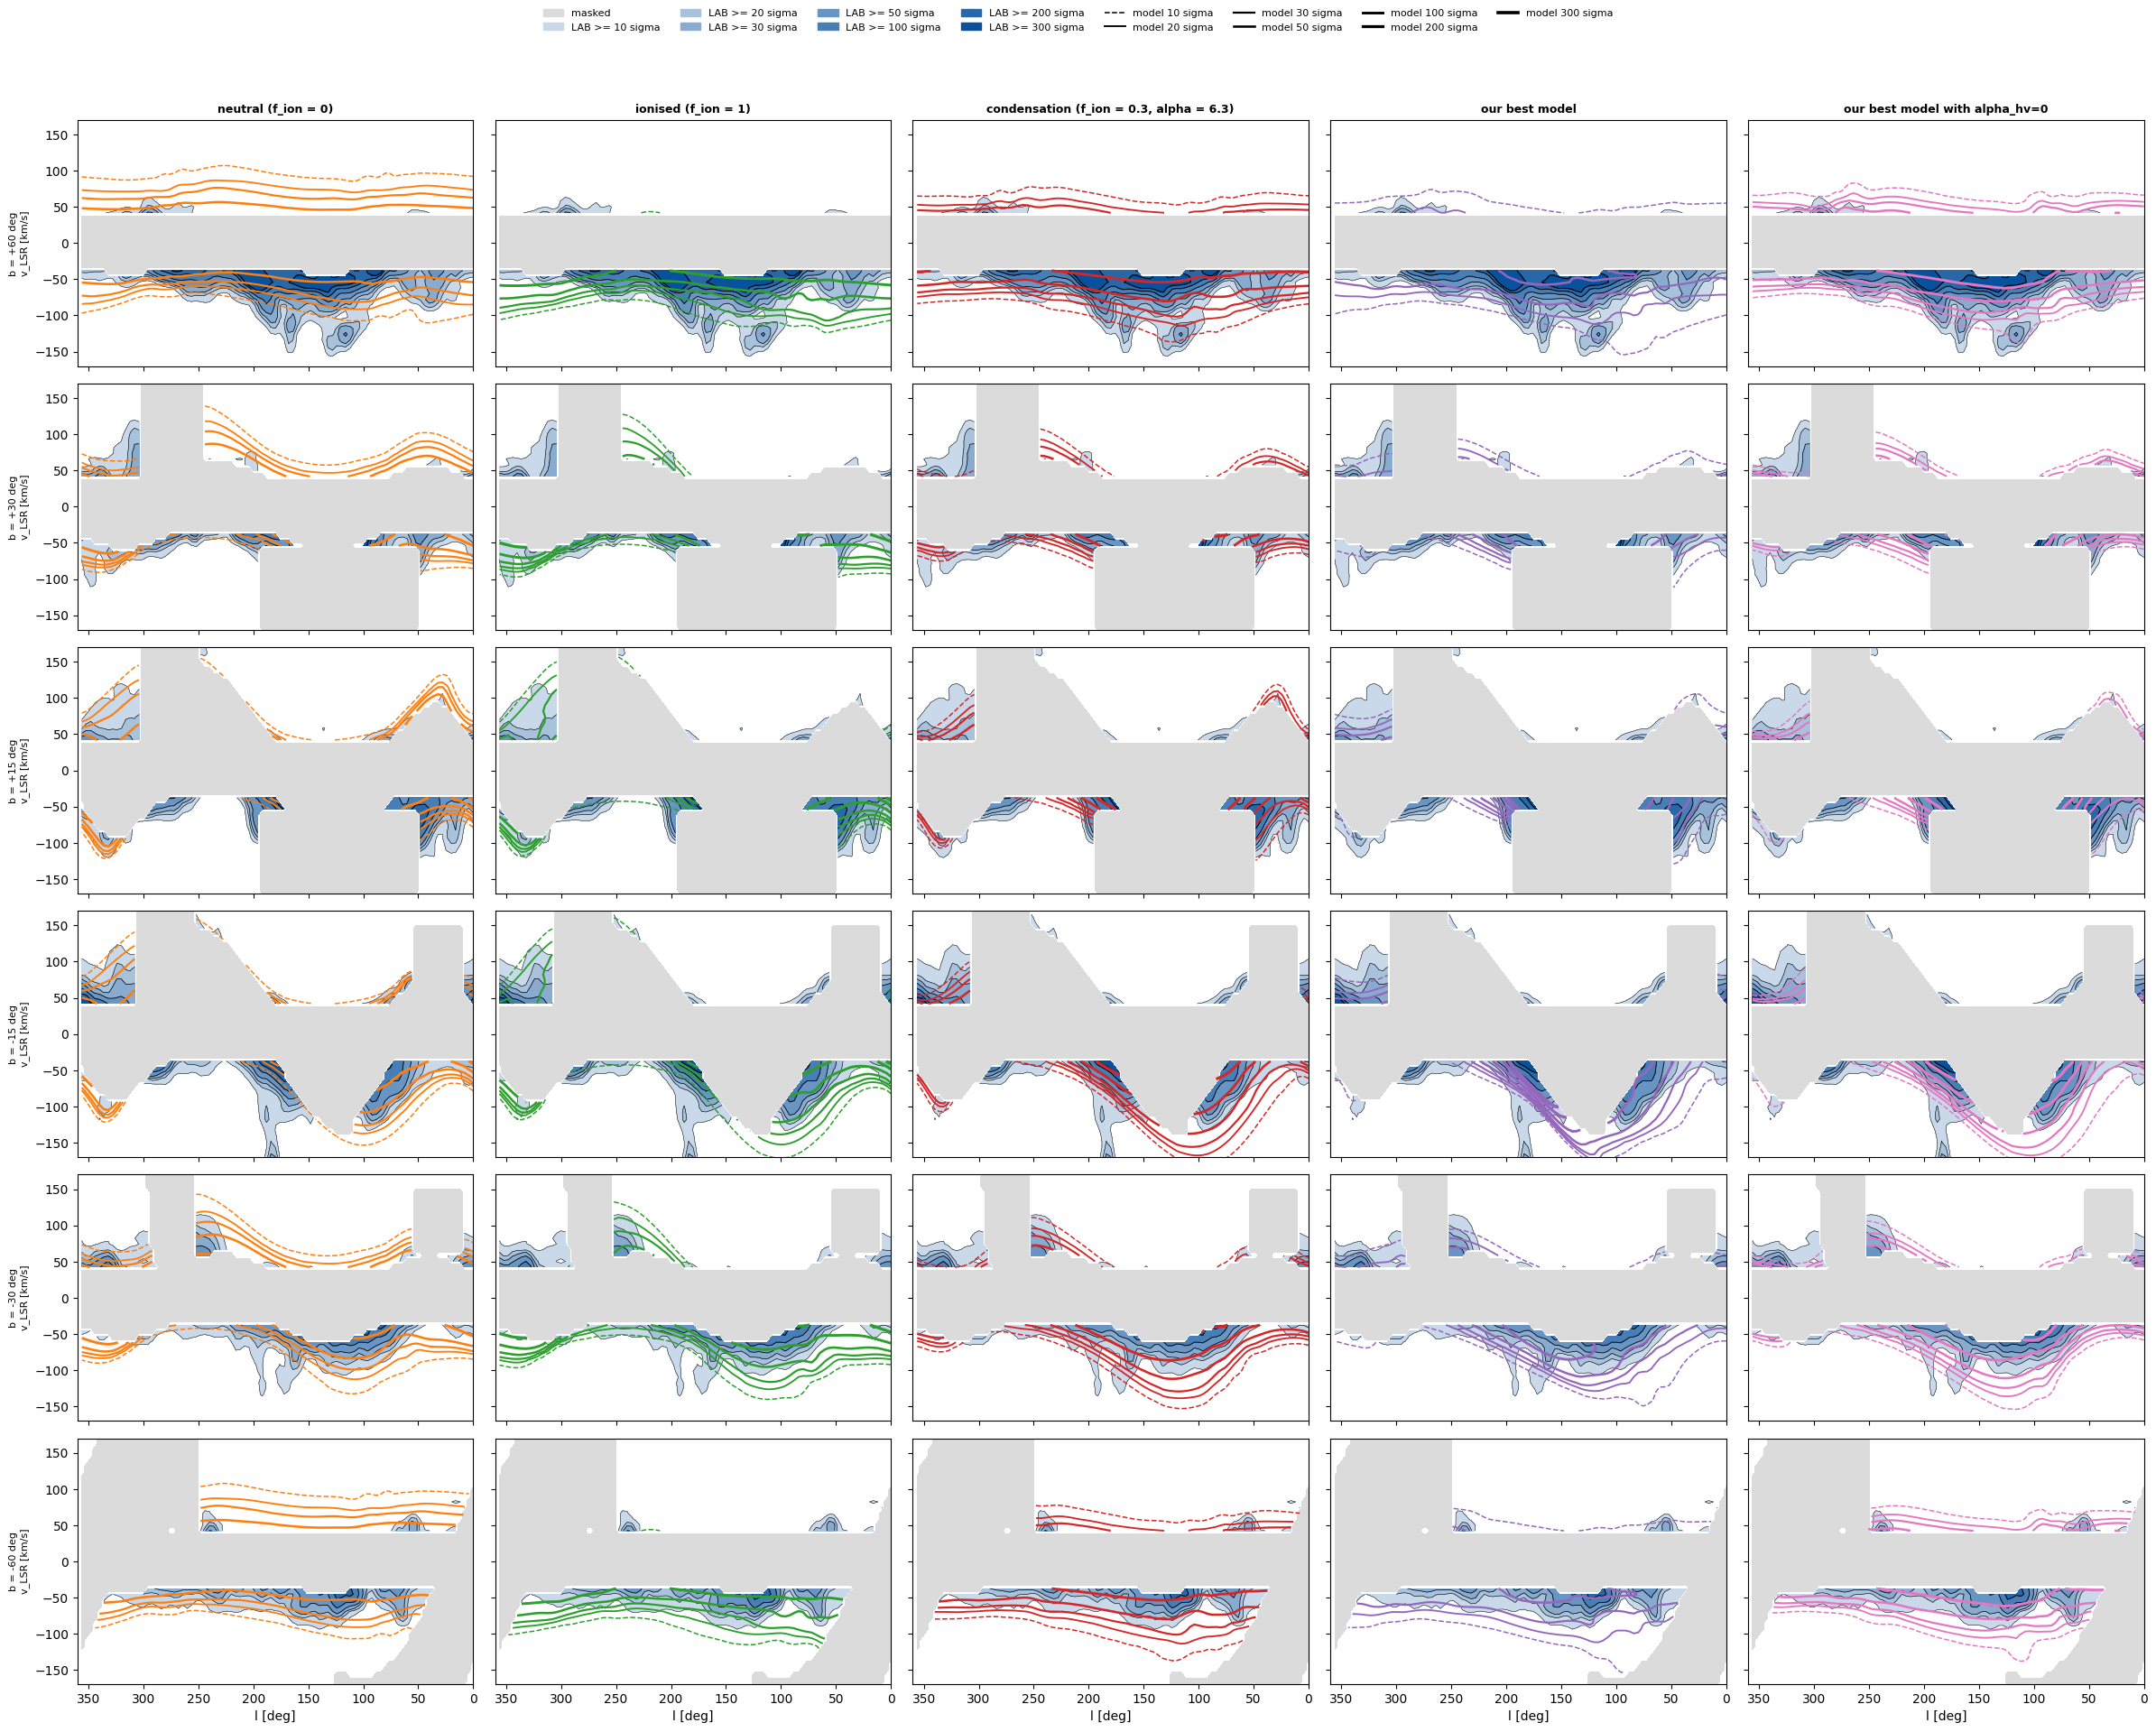

In [5]:
sc = lambda n: cmp.scaled(MODS[n], RES[n]["scale"])
models = [(sc(names_M[0]), "neutral (f_ion = 0)"), 
          (sc(names_M[3]), "ionised (f_ion = 1)"), 
          (sc(names_M[6]), "condensation (f_ion = 0.3, alpha = 6.3)"),
          (sc("best_model"), "our best model"),
          (sc("best_model_ahv0"), "our best model with alpha_hv=0")]

conf = dict(colors=("C1", "C2", "C3", "C4", "C6"), ks=(10, 20, 30, 50, 100, 200, 300))

plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60), **conf)
plt.savefig(PLOT / "lv_sigma_lab.png", dpi=150)
plt.show()

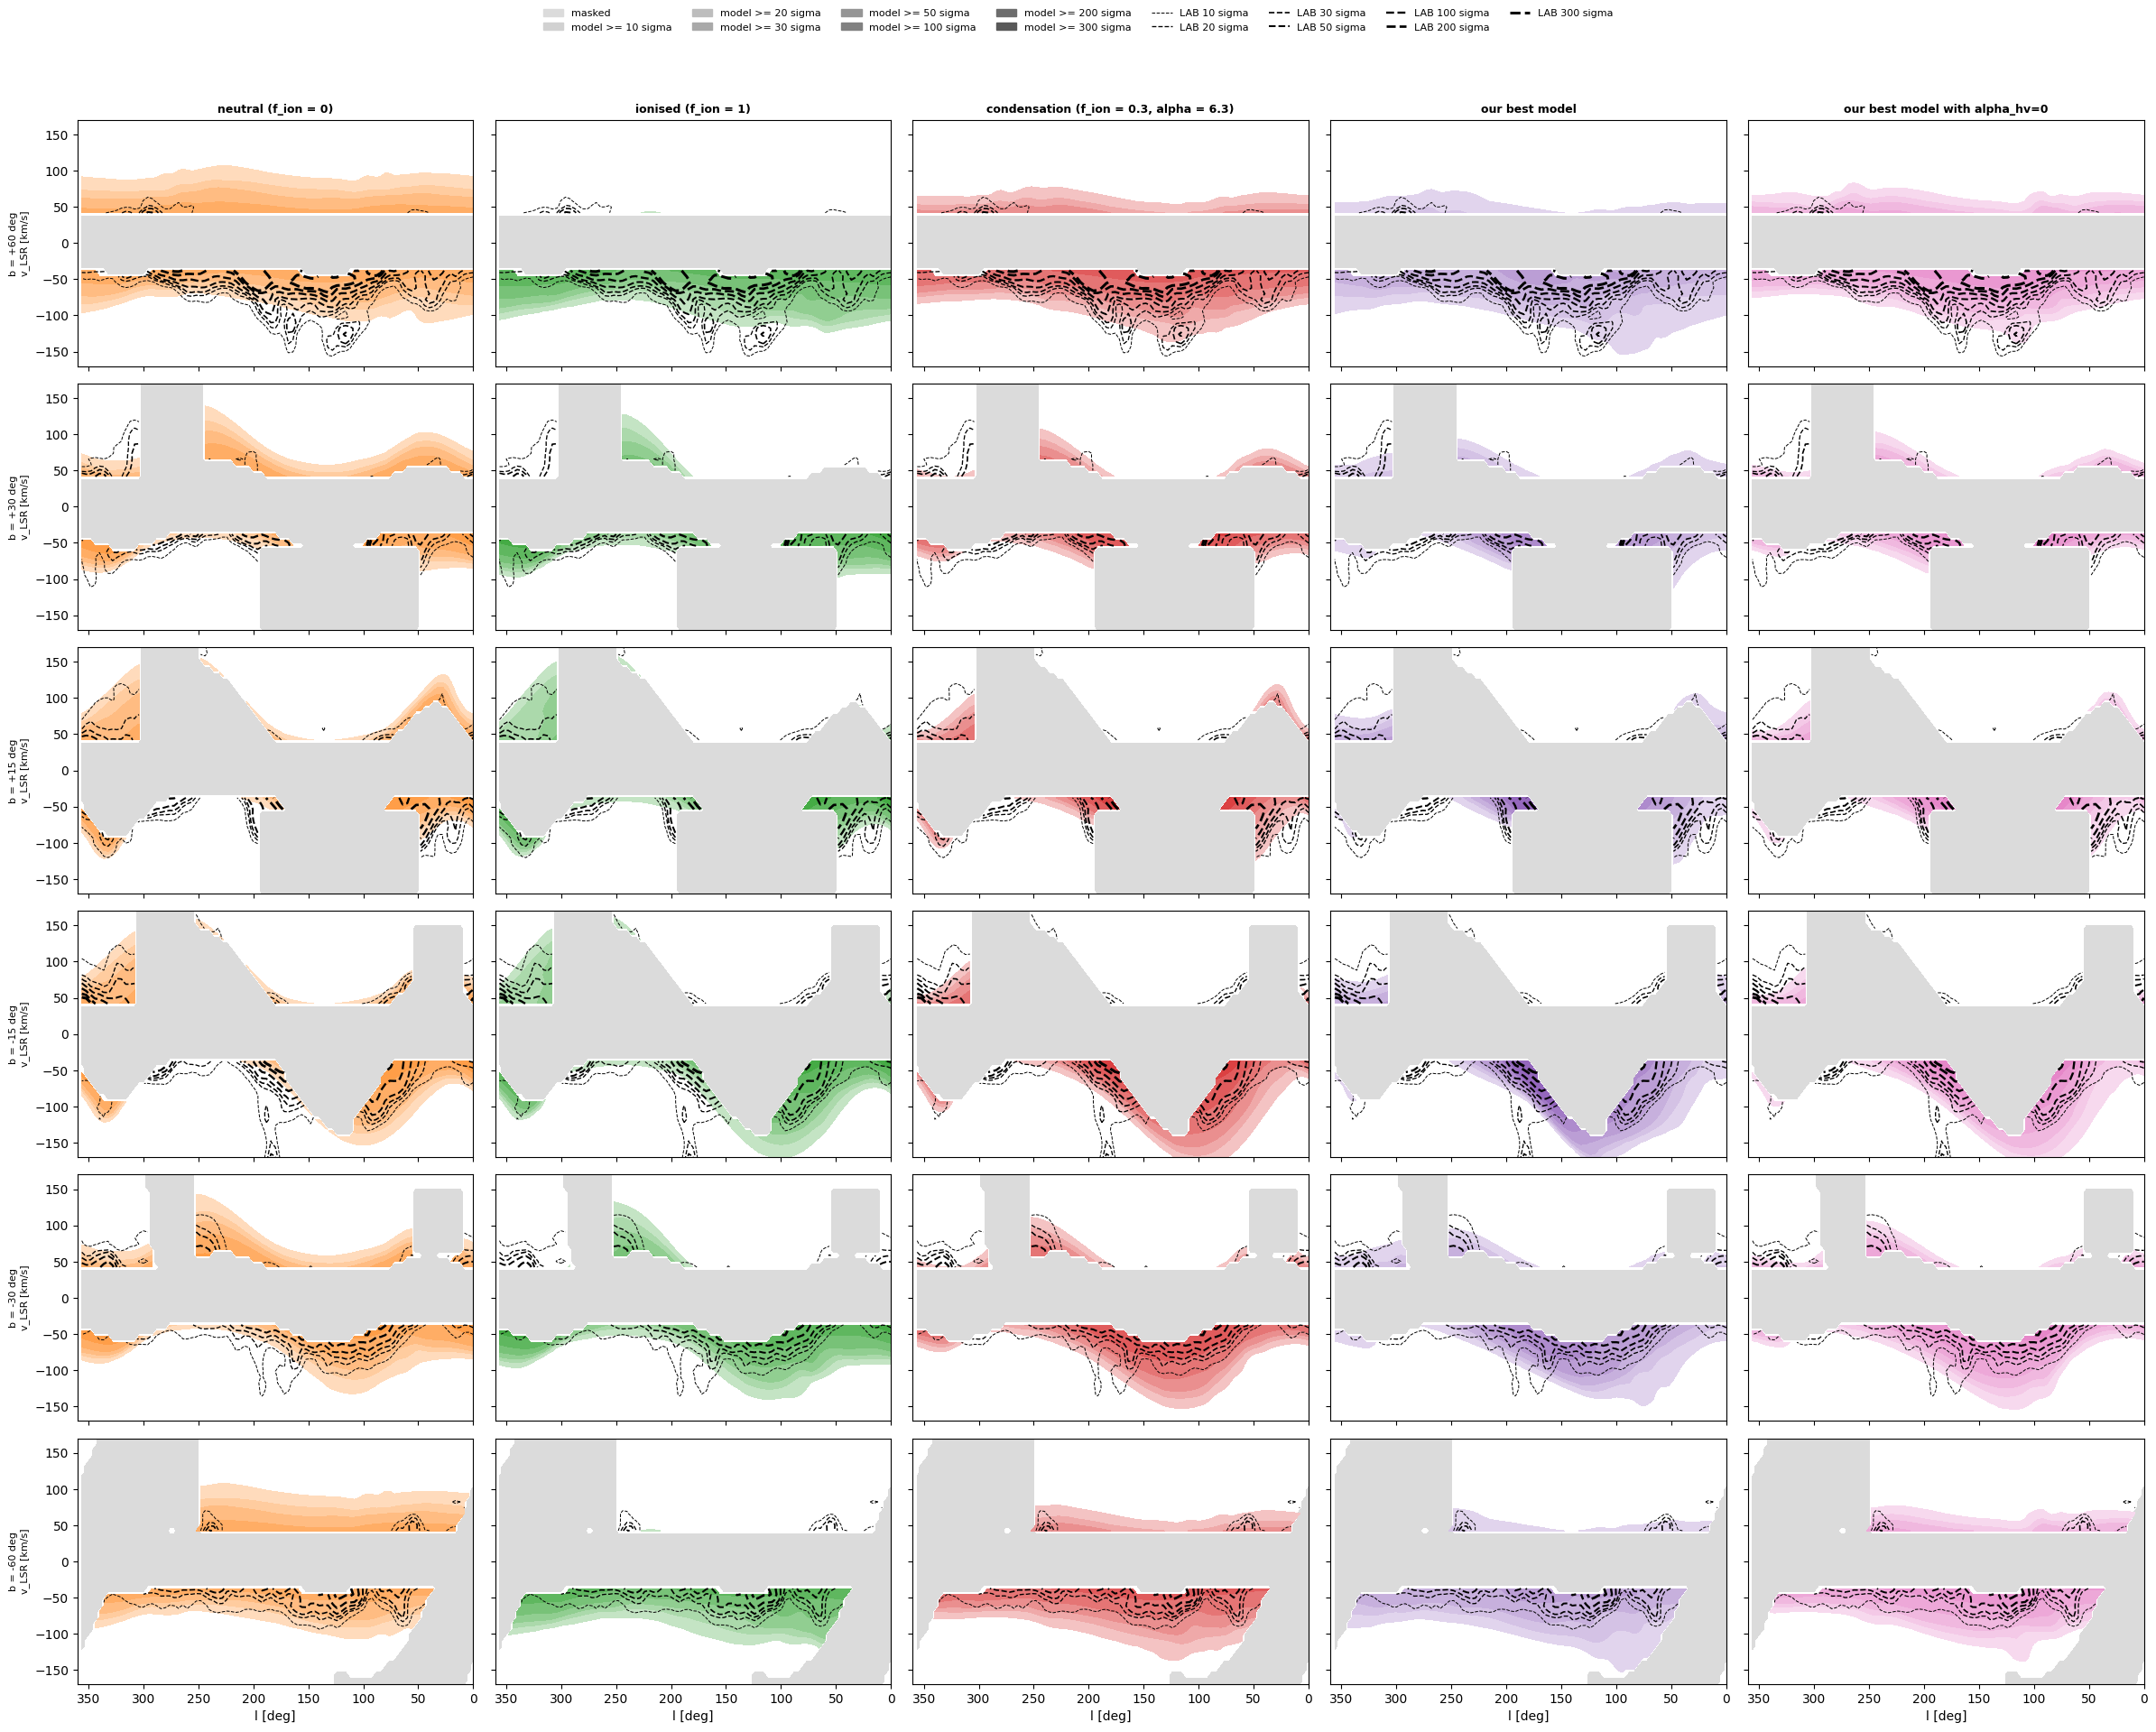

In [6]:
plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60), style="model", **conf)
plt.savefig(PLOT / "lv_sigma_model.png", dpi=150)
plt.show()

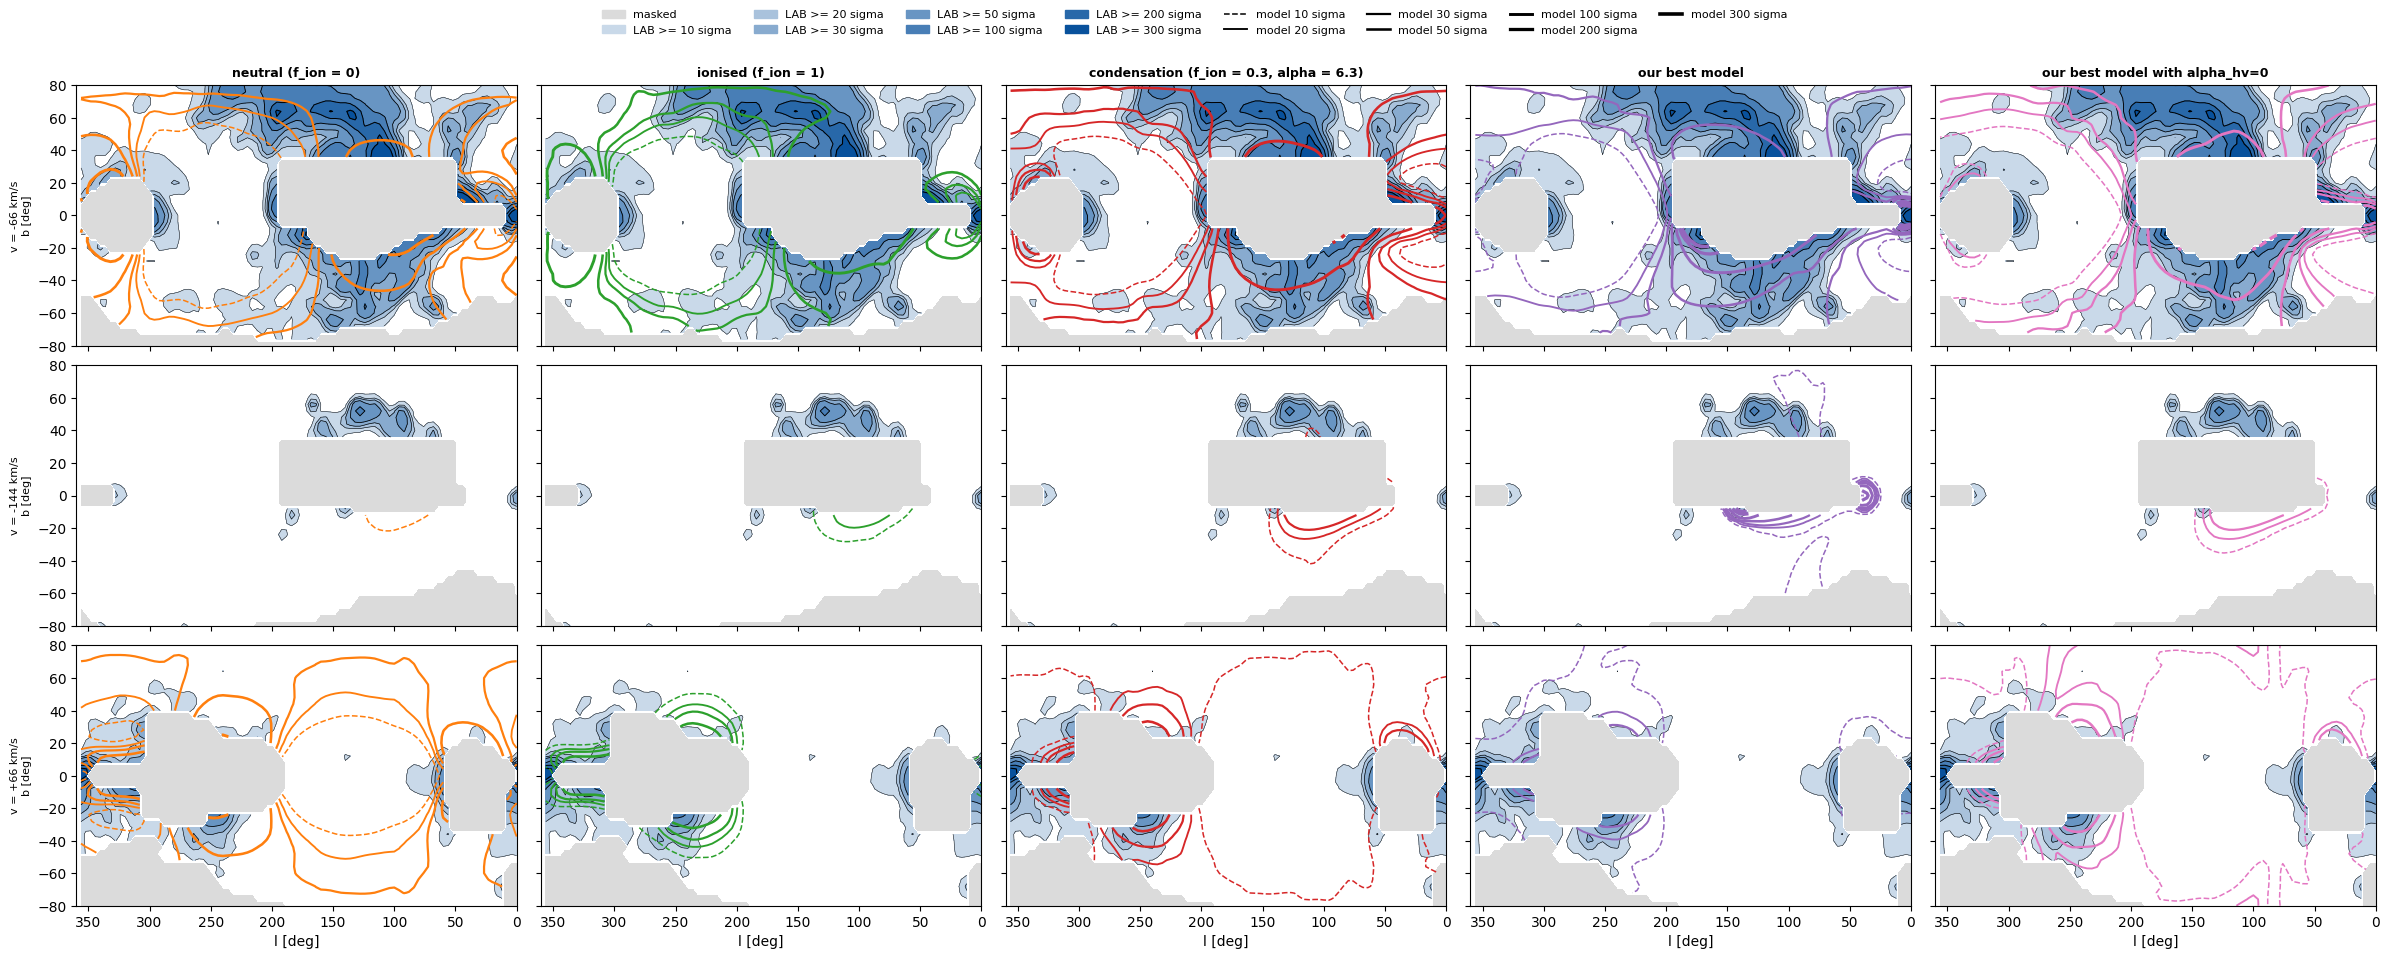

In [7]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0), **conf)
plt.savefig(PLOT / "channel_sigma_lab.png", dpi=150)
plt.show()

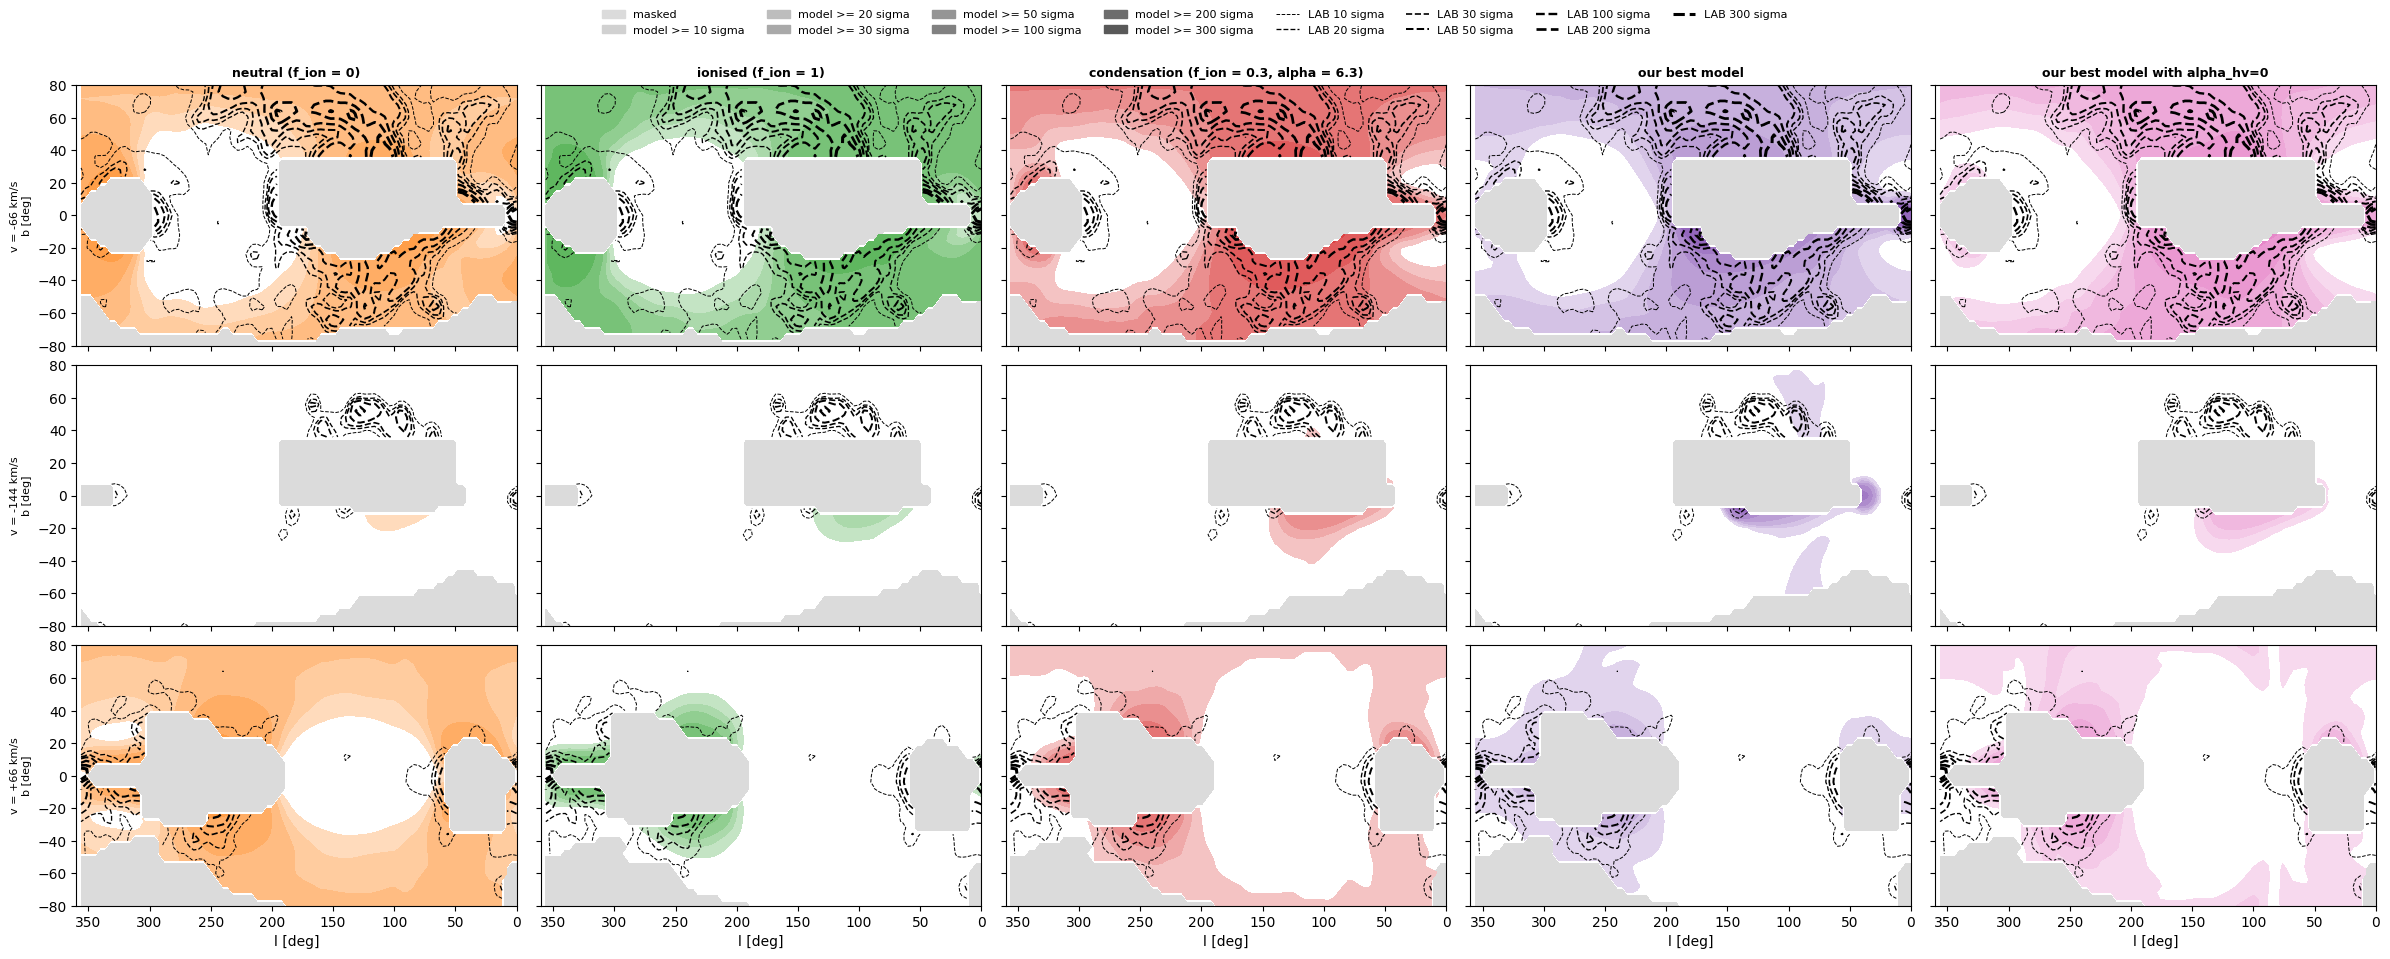

In [8]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0), style="model", **conf)
plt.savefig(PLOT / "channel_sigma_model.png", dpi=150)
plt.show()